# Modelagem — FD001

**Fase:** 03 — Modelagem  
**Subset:** FD001

**Objetivo:** Treinar e comparar 5 modelos de ML para previsão de RUL, do mais simples ao mais sofisticado, com tuning via Optuna e rastreamento via MLflow.

**Modelos (do simples ao complexo):**
1. **Ridge Regression** — baseline linear obrigatório
2. **Random Forest** — ensemble de árvores independentes
3. **XGBoost** — gradient boosting com regularização
4. **LightGBM** — gradient boosting otimizado para velocidade
5. **Stacking** — meta-modelo que combina RF + XGB + LGB

**Protocolo:** GroupKFold(5) por `unit_id` · Optuna 100 trials · MLflow tracking · Seed 42

## Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import mlflow
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from src.evaluation.metrics import rmse, mae, phm_score
from src.models.baseline import treinar_baseline_linear
from src.models.tree import (
    treinar_random_forest,
    treinar_xgboost,
    treinar_lightgbm,
    treinar_stacking,
)
from src.tracking.mlflow_setup import start_run
from src.utils.config import MODELS_DIR, PROCESSED_DIR, SEED

# Suprime logs do Optuna (mantém apenas warnings e erros)
optuna.logging.set_verbosity(optuna.logging.WARNING)

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

SUBSET    = "FD001"
N_SPLITS  = 5      # folds no GroupKFold
N_TRIALS  = 100    # trials Optuna por modelo (reduza para testes rápidos)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Subset: {SUBSET} | Folds: {N_SPLITS} | Trials Optuna: {N_TRIALS} | Seed: {SEED}")

Subset: FD001 | Folds: 5 | Trials Optuna: 100 | Seed: 42


---
## 1. Dados e Protocolo Experimental

In [2]:
train_df = pd.read_parquet(PROCESSED_DIR / f"train_{SUBSET}.parquet", engine="pyarrow")
test_df  = pd.read_parquet(PROCESSED_DIR / f"test_{SUBSET}.parquet",  engine="pyarrow")

FEATURE_COLS = [c for c in train_df.columns if c not in ("unit_id", "cycle", "rul")]

X      = train_df[FEATURE_COLS].values
y      = train_df["rul"].values.astype(float)
groups = train_df["unit_id"].values

X_test = test_df[FEATURE_COLS].values
y_test = test_df["rul"].values.astype(float)

print(f"Treino: {X.shape}  |  Teste: {X_test.shape}")
print(f"Features: {len(FEATURE_COLS)}  |  Motores treino: {np.unique(groups).size}  |  Motores teste: {len(y_test)}")

Treino: (20631, 84)  |  Teste: (100, 84)
Features: 84  |  Motores treino: 100  |  Motores teste: 100


In [3]:
# Protocolo: GroupKFold garante que um motor nunca aparece em treino e validação ao mesmo tempo
cv = GroupKFold(n_splits=N_SPLITS)

# Visualiza os folds
fold_info = []
for fold, (tr_idx, val_idx) in enumerate(cv.split(X, y, groups)):
    motores_tr  = np.unique(groups[tr_idx])
    motores_val = np.unique(groups[val_idx])
    assert len(set(motores_tr) & set(motores_val)) == 0, "Vazamento entre folds!"
    fold_info.append({
        "Fold": fold + 1,
        "Motores treino": len(motores_tr),
        "Motores val": len(motores_val),
        "Linhas treino": len(tr_idx),
        "Linhas val": len(val_idx),
    })

pd.DataFrame(fold_info).set_index("Fold")

,Motores treino,Motores val,Linhas treino,Linhas val
Fold,,,,
1,80,20,16511,4120
2,80,20,16498,4133
3,80,20,16505,4126
4,80,20,16506,4125
5,80,20,16504,4127


> **Por que GroupKFold?** Em séries temporais de motores, usar split aleatório causaria *data leakage*: o modelo veria ciclos futuros de um motor e aprenderia a "trapacear". GroupKFold garante que todos os ciclos de um motor ficam em um único fold — o mesmo motor nunca aparece em treino e validação simultaneamente.

In [4]:
# Função auxiliar: avalia um modelo instanciado nos N folds
def cv_evaluate(model_fn, X, y, groups, n_splits=N_SPLITS):
    """Retorna dict com média e desvio das 3 métricas nos folds."""
    scores = {"rmse": [], "mae": [], "phm": []}
    for tr_idx, val_idx in GroupKFold(n_splits).split(X, y, groups):
        m = model_fn()
        m.fit(X[tr_idx], y[tr_idx])
        y_pred = m.predict(X[val_idx])
        scores["rmse"].append(rmse(y[val_idx], y_pred))
        scores["mae"].append(mae(y[val_idx], y_pred))
        scores["phm"].append(phm_score(y[val_idx], y_pred))
    return {k: (float(np.mean(v)), float(np.std(v))) for k, v in scores.items()}


# Armazena resultados de todos os modelos
resultados_cv   = {}  # {model_name: {metric: (mean, std)}}
resultados_test = {}  # {model_name: {metric: value}}
modelos_finais  = {}  # {model_name: modelo treinado em X completo}

print("Funções auxiliares prontas.")

Funções auxiliares prontas.


---
## Modelo 1: Ridge Regression (Baseline)

O baseline linear serve como **piso de comparação**: se um modelo mais complexo não vencer o Ridge consistentemente, a complexidade não se justifica.

Ridge adiciona penalidade L2 ao coeficiente para evitar overfitting. O único hiperparâmetro é `alpha` (força da regularização).

In [5]:
# Optuna para Ridge: busca o melhor alpha em escala log
def ridge_objective(trial):
    alpha = trial.suggest_float("alpha", 1e-3, 1e4, log=True)
    scores = []
    for tr_idx, val_idx in GroupKFold(N_SPLITS).split(X, y, groups):
        m = Ridge(alpha=alpha, random_state=SEED)
        m.fit(X[tr_idx], y[tr_idx])
        scores.append(rmse(y[val_idx], m.predict(X[val_idx])))
    return float(np.mean(scores))

study_ridge = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="ridge_FD001",
)
study_ridge.optimize(ridge_objective, n_trials=N_TRIALS, show_progress_bar=True)

best_ridge_params = study_ridge.best_params
print(f"\nMelhor alpha: {best_ridge_params['alpha']:.4f}")
print(f"RMSE CV (Optuna best): {study_ridge.best_value:.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]


Melhor alpha: 94.2494
RMSE CV (Optuna best): 16.805


In [6]:
cv_ridge = cv_evaluate(
    lambda: Ridge(alpha=best_ridge_params["alpha"], random_state=SEED),
    X, y, groups
)
resultados_cv["Ridge"] = cv_ridge

modelo_ridge = treinar_baseline_linear(X, y, alpha=best_ridge_params["alpha"])
modelos_finais["Ridge"] = modelo_ridge

y_pred_ridge = modelo_ridge.predict(X_test)
resultados_test["Ridge"] = {
    "rmse": rmse(y_test, y_pred_ridge),
    "mae":  mae(y_test, y_pred_ridge),
    "phm":  phm_score(y_test, y_pred_ridge),
}

_study_path = str(MODELS_DIR / "study_ridge.pkl")
joblib.dump(study_ridge, _study_path)

with start_run(f"cmapss_{SUBSET}_modeling", run_name="ridge",
               tags={"model": "ridge", "subset": SUBSET}):
    mlflow.log_params(best_ridge_params)
    mlflow.log_metrics({
        "cv_rmse": cv_ridge["rmse"][0], "cv_mae": cv_ridge["mae"][0], "cv_phm": cv_ridge["phm"][0],
        "test_rmse": resultados_test["Ridge"]["rmse"],
        "test_mae":  resultados_test["Ridge"]["mae"],
        "test_phm":  resultados_test["Ridge"]["phm"],
    })
    mlflow.sklearn.log_model(modelo_ridge, "model")
    mlflow.log_artifact(_study_path, "optuna")

print(f"Ridge  →  CV RMSE: {cv_ridge['rmse'][0]:.3f} ± {cv_ridge['rmse'][1]:.3f}  "
      f"| Teste RMSE: {resultados_test['Ridge']['rmse']:.3f}")

2026/07/28 16:18:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Ridge  →  CV RMSE: 16.805 ± 0.509  | Teste RMSE: 18.595


---
## Modelo 2: Random Forest

Random Forest combina centenas de árvores de decisão treinadas em subconjuntos aleatórios dos dados e features. A previsão final é a média das previsões individuais — isso reduz a variância sem aumentar o viés.

**Hiperparâmetros tunados:**
- `n_estimators`: número de árvores
- `max_depth`: profundidade máxima
- `min_samples_leaf`: tamanho mínimo das folhas
- `max_features`: fração de features por split

In [7]:
def rf_objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 100, 400, step=50),
        "max_depth":        trial.suggest_int("max_depth", 5, 25),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features":     trial.suggest_float("max_features", 0.4, 1.0),
    }
    scores = []
    for tr_idx, val_idx in GroupKFold(N_SPLITS).split(X, y, groups):
        m = RandomForestRegressor(random_state=SEED, n_jobs=-1, **params)
        m.fit(X[tr_idx], y[tr_idx])
        scores.append(rmse(y[val_idx], m.predict(X[val_idx])))
    return float(np.mean(scores))

study_rf = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="rf_FD001",
)
study_rf.optimize(rf_objective, n_trials=N_TRIALS, show_progress_bar=True)

best_rf_params = study_rf.best_params
print(f"\nMelhores params RF: {best_rf_params}")
print(f"RMSE CV (Optuna best): {study_rf.best_value:.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]


Melhores params RF: {'n_estimators': 400, 'max_depth': 14, 'min_samples_leaf': 4, 'max_features': 0.41077712536889205}
RMSE CV (Optuna best): 12.673


In [8]:
cv_rf = cv_evaluate(
    lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1, **best_rf_params),
    X, y, groups
)
resultados_cv["Random Forest"] = cv_rf

modelo_rf = treinar_random_forest(X, y, **best_rf_params)
modelos_finais["Random Forest"] = modelo_rf

y_pred_rf = modelo_rf.predict(X_test)
resultados_test["Random Forest"] = {
    "rmse": rmse(y_test, y_pred_rf),
    "mae":  mae(y_test, y_pred_rf),
    "phm":  phm_score(y_test, y_pred_rf),
}

_study_path = str(MODELS_DIR / "study_rf.pkl")
joblib.dump(study_rf, _study_path)

with start_run(f"cmapss_{SUBSET}_modeling", run_name="random_forest",
               tags={"model": "random_forest", "subset": SUBSET}):
    mlflow.log_params(best_rf_params)
    mlflow.log_metrics({
        "cv_rmse": cv_rf["rmse"][0], "cv_mae": cv_rf["mae"][0], "cv_phm": cv_rf["phm"][0],
        "test_rmse": resultados_test["Random Forest"]["rmse"],
        "test_mae":  resultados_test["Random Forest"]["mae"],
        "test_phm":  resultados_test["Random Forest"]["phm"],
    })
    mlflow.sklearn.log_model(modelo_rf, "model")
    mlflow.log_artifact(_study_path, "optuna")

print(f"RF  →  CV RMSE: {cv_rf['rmse'][0]:.3f} ± {cv_rf['rmse'][1]:.3f}  "
      f"| Teste RMSE: {resultados_test['Random Forest']['rmse']:.3f}")

2026/07/28 17:41:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RF  →  CV RMSE: 12.673 ± 1.021  | Teste RMSE: 13.417


---
## Modelo 3: XGBoost

XGBoost treina árvores **sequencialmente**, onde cada árvore corrige os erros da anterior. Ao contrário do RF (paralelismo), o boosting constrói modelos incrementais — geralmente mais preciso, mas mais sensível a hiperparâmetros e propenso a overfitting sem regularização adequada.

**Hiperparâmetros adicionais:** `learning_rate`, `subsample`, `colsample_bytree`, `reg_alpha` (L1), `reg_lambda` (L2).

In [9]:
def xgb_objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth":        trial.suggest_int("max_depth", 3, 10),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample":        trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha":        trial.suggest_float("reg_alpha", 0.0, 5.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 0.5, 5.0),
    }
    scores = []
    for tr_idx, val_idx in GroupKFold(N_SPLITS).split(X, y, groups):
        m = XGBRegressor(random_state=SEED, n_jobs=-1, eval_metric="rmse",
                         verbosity=0, **params)
        m.fit(X[tr_idx], y[tr_idx])
        scores.append(rmse(y[val_idx], m.predict(X[val_idx])))
    return float(np.mean(scores))

study_xgb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="xgb_FD001",
)
study_xgb.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=True)

best_xgb_params = study_xgb.best_params
print(f"\nMelhores params XGB: {best_xgb_params}")
print(f"RMSE CV (Optuna best): {study_xgb.best_value:.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]


Melhores params XGB: {'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.02163023675165673, 'subsample': 0.6807171468064964, 'colsample_bytree': 0.6061878459599168, 'reg_alpha': 3.5770455829545056, 'reg_lambda': 4.299280943964039}
RMSE CV (Optuna best): 12.271


In [10]:
cv_xgb = cv_evaluate(
    lambda: XGBRegressor(random_state=SEED, n_jobs=-1, eval_metric="rmse",
                         verbosity=0, **best_xgb_params),
    X, y, groups
)
resultados_cv["XGBoost"] = cv_xgb

modelo_xgb = treinar_xgboost(X, y, **best_xgb_params)
modelos_finais["XGBoost"] = modelo_xgb

y_pred_xgb = modelo_xgb.predict(X_test)
resultados_test["XGBoost"] = {
    "rmse": rmse(y_test, y_pred_xgb),
    "mae":  mae(y_test, y_pred_xgb),
    "phm":  phm_score(y_test, y_pred_xgb),
}

_study_path = str(MODELS_DIR / "study_xgb.pkl")
joblib.dump(study_xgb, _study_path)

with start_run(f"cmapss_{SUBSET}_modeling", run_name="xgboost",
               tags={"model": "xgboost", "subset": SUBSET}):
    mlflow.log_params(best_xgb_params)
    mlflow.log_metrics({
        "cv_rmse": cv_xgb["rmse"][0], "cv_mae": cv_xgb["mae"][0], "cv_phm": cv_xgb["phm"][0],
        "test_rmse": resultados_test["XGBoost"]["rmse"],
        "test_mae":  resultados_test["XGBoost"]["mae"],
        "test_phm":  resultados_test["XGBoost"]["phm"],
    })
    mlflow.sklearn.log_model(
        modelo_xgb, "model",
        skops_trusted_types=["xgboost.core.Booster", "xgboost.sklearn.XGBRegressor"],
    )
    mlflow.log_artifact(_study_path, "optuna")

print(f"XGB  →  CV RMSE: {cv_xgb['rmse'][0]:.3f} ± {cv_xgb['rmse'][1]:.3f}  "
      f"| Teste RMSE: {resultados_test['XGBoost']['rmse']:.3f}")

2026/07/28 17:54:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


XGB  →  CV RMSE: 12.271 ± 0.675  | Teste RMSE: 12.499


---
## Modelo 4: LightGBM

LightGBM é uma variante de gradient boosting que usa crescimento de árvore **por folha** (*leaf-wise*) em vez de por nível (*level-wise*). Isso torna o treinamento muito mais rápido e frequentemente produz modelos mais precisos, especialmente em datasets maiores.

**Diferença principal do XGBoost:** `num_leaves` substitui `max_depth` como principal controle de complexidade.

In [11]:
def lgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 100, 500, step=50),
        "num_leaves":        trial.suggest_int("num_leaves", 20, 150),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 0.0, 5.0),
        "reg_lambda":        trial.suggest_float("reg_lambda", 0.0, 5.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
    }
    scores = []
    for tr_idx, val_idx in GroupKFold(N_SPLITS).split(X, y, groups):
        m = LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1, **params)
        m.fit(X[tr_idx], y[tr_idx])
        scores.append(rmse(y[val_idx], m.predict(X[val_idx])))
    return float(np.mean(scores))

study_lgb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="lgb_FD001",
)
study_lgb.optimize(lgb_objective, n_trials=N_TRIALS, show_progress_bar=True)

best_lgb_params = study_lgb.best_params
print(f"\nMelhores params LGB: {best_lgb_params}")
print(f"RMSE CV (Optuna best): {study_lgb.best_value:.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]


Melhores params LGB: {'n_estimators': 300, 'num_leaves': 30, 'learning_rate': 0.02047213066054954, 'subsample': 0.6271524432163414, 'colsample_bytree': 0.6138220709064475, 'reg_alpha': 2.105365810697189, 'reg_lambda': 1.363858350246486, 'min_child_samples': 49}
RMSE CV (Optuna best): 12.397


In [12]:
cv_lgb = cv_evaluate(
    lambda: LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1, **best_lgb_params),
    X, y, groups
)
resultados_cv["LightGBM"] = cv_lgb

modelo_lgb = treinar_lightgbm(X, y, **best_lgb_params)
modelos_finais["LightGBM"] = modelo_lgb

y_pred_lgb = modelo_lgb.predict(X_test)
resultados_test["LightGBM"] = {
    "rmse": rmse(y_test, y_pred_lgb),
    "mae":  mae(y_test, y_pred_lgb),
    "phm":  phm_score(y_test, y_pred_lgb),
}

_study_path = str(MODELS_DIR / "study_lgb.pkl")
joblib.dump(study_lgb, _study_path)

with start_run(f"cmapss_{SUBSET}_modeling", run_name="lightgbm",
               tags={"model": "lightgbm", "subset": SUBSET}):
    mlflow.log_params(best_lgb_params)
    mlflow.log_metrics({
        "cv_rmse": cv_lgb["rmse"][0], "cv_mae": cv_lgb["mae"][0], "cv_phm": cv_lgb["phm"][0],
        "test_rmse": resultados_test["LightGBM"]["rmse"],
        "test_mae":  resultados_test["LightGBM"]["mae"],
        "test_phm":  resultados_test["LightGBM"]["phm"],
    })
    mlflow.sklearn.log_model(
        modelo_lgb, "model",
        skops_trusted_types=["lightgbm.basic.Booster", "lightgbm.sklearn.LGBMRegressor", "collections.OrderedDict"],
    )
    mlflow.log_artifact(_study_path, "optuna")

print(f"LGB  →  CV RMSE: {cv_lgb['rmse'][0]:.3f} ± {cv_lgb['rmse'][1]:.3f}  "
      f"| Teste RMSE: {resultados_test['LightGBM']['rmse']:.3f}")

2026/07/28 18:02:09 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


LGB  →  CV RMSE: 12.397 ± 0.780  | Teste RMSE: 12.793


---
## Modelo 5: Stacking Ensemble

O Stacking combina as previsões de múltiplos modelos base usando um **meta-modelo** que aprende como pesar cada um.

**Como funciona:**
1. Cada modelo base (RF, XGB, LGB) gera previsões **out-of-fold** sobre o treino (via GroupKFold)
2. O meta-modelo (Ridge) aprende a combinação ótima dessas previsões
3. Para o teste: cada base model é retreinado no treino completo; o meta-modelo combina as previsões

**Hiperparâmetros:** usa os melhores params já encontrados para cada modelo base.

In [13]:
%%time
# Stacking usa os best_params de cada modelo base
# GroupKFold pré-computado garante consistência com o protocolo
modelo_stacking = treinar_stacking(
    X, y, groups,
    rf_params=best_rf_params,
    xgb_params=best_xgb_params,
    lgb_params=best_lgb_params,
)
print("Stacking treinado.")

Stacking treinado.
CPU times: total: 2.42 s
Wall time: 3min 35s


In [14]:
# CV do stacking: avalia o ensemble com GroupKFold
cv_splits_stacking = list(GroupKFold(N_SPLITS).split(X, y, groups))

scores_stacking = {"rmse": [], "mae": [], "phm": []}
for tr_idx, val_idx in cv_splits_stacking:
    m = treinar_stacking(
        X[tr_idx], y[tr_idx], groups[tr_idx],
        rf_params=best_rf_params,
        xgb_params=best_xgb_params,
        lgb_params=best_lgb_params,
    )
    y_pred_fold = m.predict(X[val_idx])
    scores_stacking["rmse"].append(rmse(y[val_idx], y_pred_fold))
    scores_stacking["mae"].append(mae(y[val_idx], y_pred_fold))
    scores_stacking["phm"].append(phm_score(y[val_idx], y_pred_fold))

cv_stacking = {k: (float(np.mean(v)), float(np.std(v))) for k, v in scores_stacking.items()}
resultados_cv["Stacking"] = cv_stacking
modelos_finais["Stacking"] = modelo_stacking

y_pred_stacking = modelo_stacking.predict(X_test)
resultados_test["Stacking"] = {
    "rmse": rmse(y_test, y_pred_stacking),
    "mae":  mae(y_test, y_pred_stacking),
    "phm":  phm_score(y_test, y_pred_stacking),
}

with start_run(f"cmapss_{SUBSET}_modeling", run_name="stacking",
               tags={"model": "stacking", "subset": SUBSET}):
    mlflow.log_params({"base_models": "rf+xgb+lgb", "meta_model": "ridge", "cv": "GroupKFold(5)"})
    mlflow.log_metrics({
        "cv_rmse": cv_stacking["rmse"][0], "cv_mae": cv_stacking["mae"][0],
        "cv_phm": cv_stacking["phm"][0],
        "test_rmse": resultados_test["Stacking"]["rmse"],
        "test_mae":  resultados_test["Stacking"]["mae"],
        "test_phm":  resultados_test["Stacking"]["phm"],
    })
    mlflow.sklearn.log_model(
        modelo_stacking, "model",
        skops_trusted_types=["xgboost.core.Booster", "xgboost.sklearn.XGBRegressor","lightgbm.basic.Booster", "lightgbm.sklearn.LGBMRegressor","collections.OrderedDict", "sklearn.utils._bunch.Bunch",],
    )

print(f"Stacking  →  CV RMSE: {cv_stacking['rmse'][0]:.3f} ± {cv_stacking['rmse'][1]:.3f}  "
      f"| Teste RMSE: {resultados_test['Stacking']['rmse']:.3f}")

2026/07/28 18:18:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Stacking  →  CV RMSE: 12.228 ± 0.704  | Teste RMSE: 12.737


---
## Comparação Entre Modelos

In [15]:
# Tabela principal
linhas = []
for nome in ["Ridge", "Random Forest", "XGBoost", "LightGBM", "Stacking"]:
    cv  = resultados_cv[nome]
    tst = resultados_test[nome]
    linhas.append({
        "Modelo": nome,
        "CV RMSE":       f"{cv['rmse'][0]:.2f} ± {cv['rmse'][1]:.2f}",
        "CV MAE":        f"{cv['mae'][0]:.2f} ± {cv['mae'][1]:.2f}",
        "CV PHM Score":  f"{cv['phm'][0]:.0f} ± {cv['phm'][1]:.0f}",
        "Teste RMSE":    round(tst["rmse"], 2),
        "Teste MAE":     round(tst["mae"], 2),
        "Teste PHM":     round(tst["phm"], 0),
    })

df_resultados = pd.DataFrame(linhas).set_index("Modelo")

# Destaca o melhor em cada coluna numérica de teste
def highlight_min(s):
    is_min = s == s.min()
    return ["background-color: #d4edda; font-weight: bold" if v else "" for v in is_min]

df_resultados.style.apply(highlight_min, subset=["Teste RMSE", "Teste MAE", "Teste PHM"])

,CV RMSE,CV MAE,CV PHM Score,Teste RMSE,Teste MAE,Teste PHM
Modelo,,,,,,
Ridge,16.81 ± 0.51,13.73 ± 0.69,19057 ± 846,18.590000,14.850000,501.000000
Random Forest,12.67 ± 1.02,9.11 ± 0.81,12403 ± 1754,13.420000,10.020000,253.000000
XGBoost,12.27 ± 0.67,8.70 ± 0.58,11501 ± 1287,12.500000,9.040000,206.000000
LightGBM,12.40 ± 0.78,8.73 ± 0.65,11740 ± 1524,12.790000,9.270000,222.000000
Stacking,12.23 ± 0.70,8.55 ± 0.62,11841 ± 1291,12.740000,9.180000,220.000000


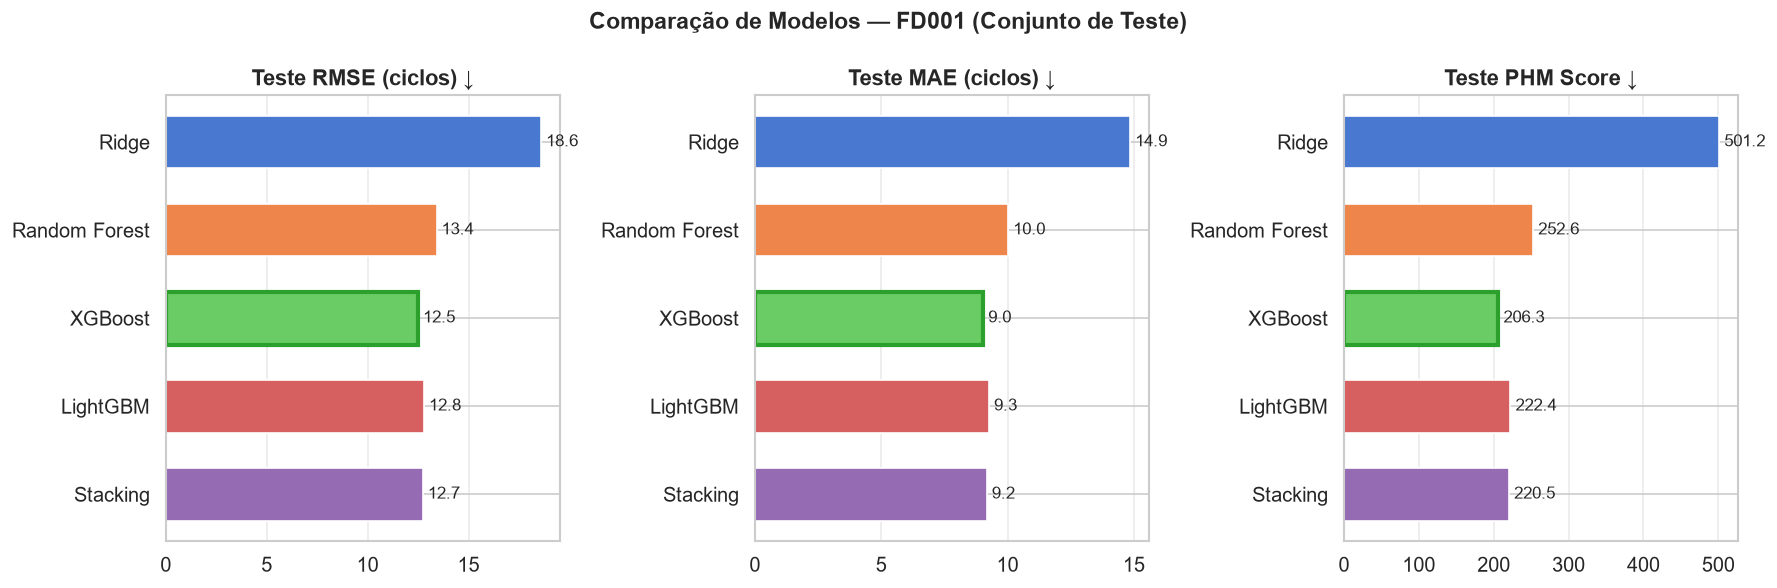

In [16]:
# Gráfico comparativo — métricas no conjunto de teste
modelos_ordem = ["Ridge", "Random Forest", "XGBoost", "LightGBM", "Stacking"]
cores = sns.color_palette("muted", len(modelos_ordem))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metricas_plot = [
    ("rmse",  "Teste RMSE (ciclos) ↓"),
    ("mae",   "Teste MAE (ciclos) ↓"),
    ("phm",   "Teste PHM Score ↓"),
]

for ax, (metrica, titulo) in zip(axes, metricas_plot):
    valores = [resultados_test[m][metrica] for m in modelos_ordem]
    bars = ax.barh(modelos_ordem, valores, color=cores, edgecolor="white", height=0.6)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10)
    # Marca o melhor
    idx_min = int(np.argmin(valores))
    bars[idx_min].set_edgecolor("#2ca02c")
    bars[idx_min].set_linewidth(2.5)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.4)

fig.suptitle(f"Comparação de Modelos — FD001 (Conjunto de Teste)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

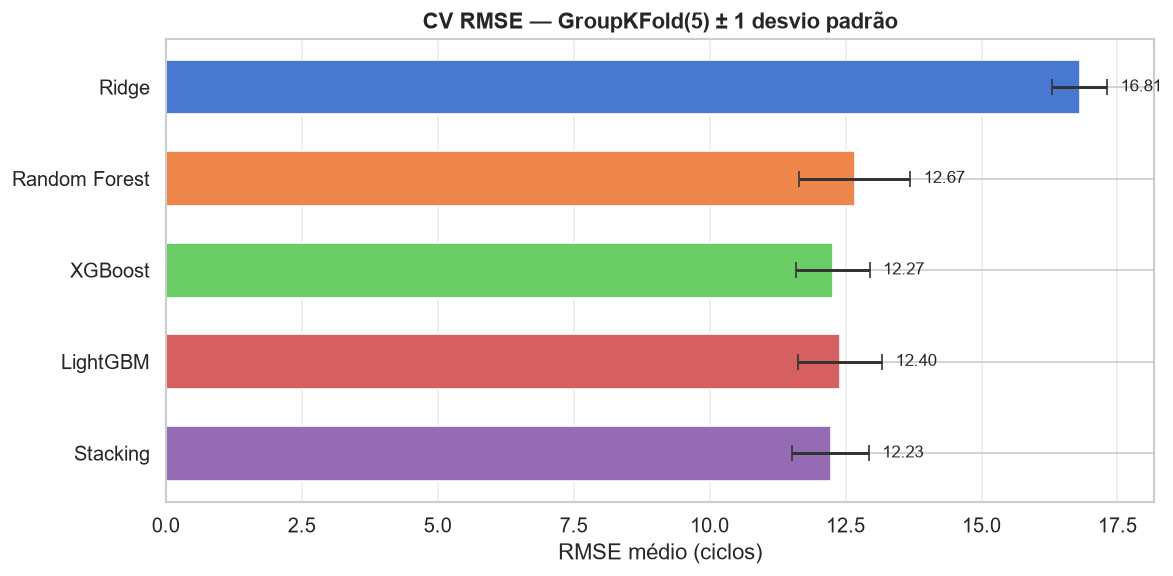

In [17]:
# CV RMSE com intervalo de confiança (±1 std)
fig, ax = plt.subplots(figsize=(10, 5))

cv_rmse_means = [resultados_cv[m]["rmse"][0] for m in modelos_ordem]
cv_rmse_stds  = [resultados_cv[m]["rmse"][1] for m in modelos_ordem]

bars = ax.barh(modelos_ordem, cv_rmse_means, xerr=cv_rmse_stds,
               color=cores, edgecolor="white", height=0.6,
               error_kw={"elinewidth": 1.8, "capsize": 5, "ecolor": "#333"})
ax.bar_label(bars, labels=[f"{v:.2f}" for v in cv_rmse_means],
             padding=8, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("RMSE médio (ciclos)")
ax.set_title("CV RMSE — GroupKFold(5) ± 1 desvio padrão", fontweight="bold")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

---
## Convergência do Optuna — Validando o Budget de 100 Trials

Para garantir que 100 trials foram suficientes, visualizamos a **curva de convergência** de cada modelo: o melhor RMSE encontrado até cada trial. Uma curva que "aplaina" indica que mais trials não trariam ganho significativo — o budget foi adequado.

Esse gráfico serve como evidência metodológica para o artigo: o processo de otimização foi conduzido até a convergência, não truncado arbitrariamente.

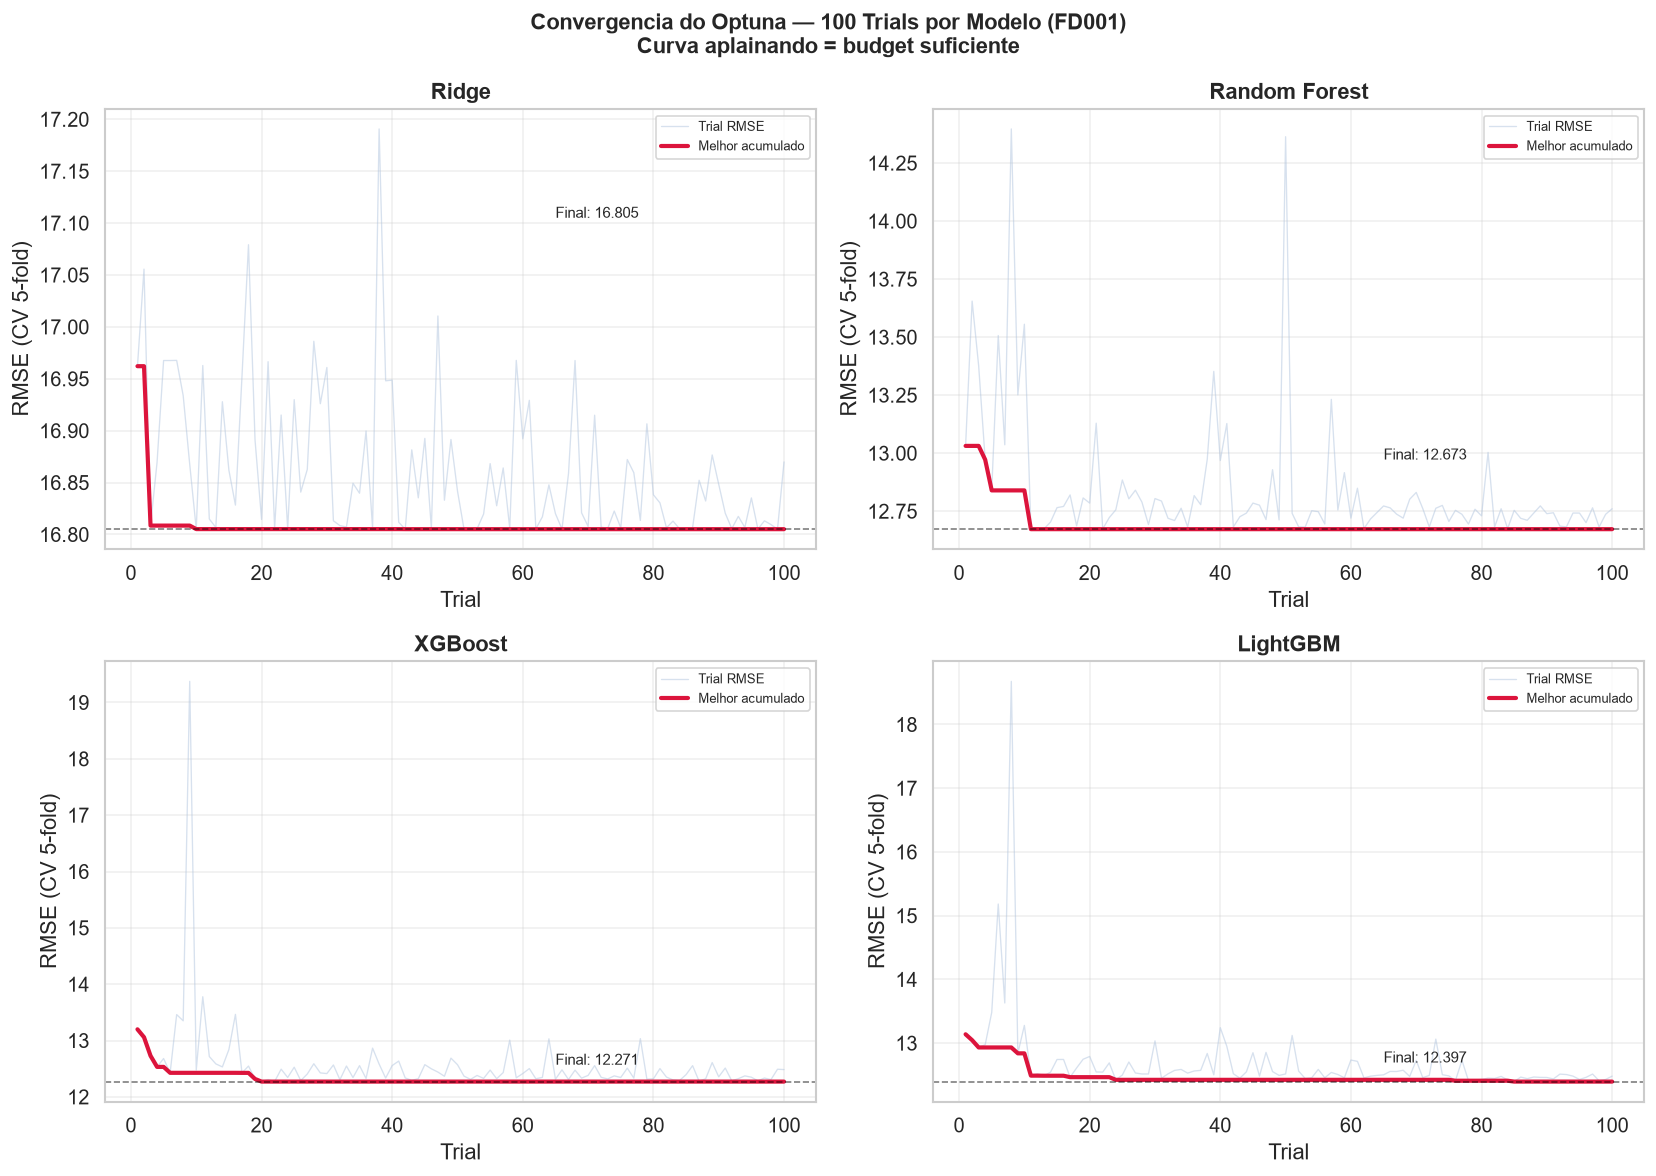

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
studies_map = {
    "Ridge":         study_ridge,
    "Random Forest": study_rf,
    "XGBoost":       study_xgb,
    "LightGBM":      study_lgb,
}

for ax, (nome, study) in zip(axes.flatten(), studies_map.items()):
    valores = [t.value for t in study.trials if t.value is not None]
    best_so_far = [min(valores[:i + 1]) for i in range(len(valores))]

    ax.plot(range(1, len(valores) + 1), valores,
            color="lightsteelblue", alpha=0.5, lw=0.8, label="Trial RMSE")
    ax.plot(range(1, len(best_so_far) + 1), best_so_far,
            color="crimson", lw=2.5, label="Melhor acumulado")
    ax.axhline(best_so_far[-1], color="black", lw=1, linestyle="--", alpha=0.5)
    ax.text(len(best_so_far) * 0.65, best_so_far[-1] + 0.3,
            f"Final: {best_so_far[-1]:.3f}", fontsize=9)
    ax.set_xlabel("Trial")
    ax.set_ylabel("RMSE (CV 5-fold)")
    ax.set_title(nome, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle(
    "Convergencia do Optuna — 100 Trials por Modelo (FD001)\n"
    "Curva aplainando = budget suficiente",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

---
## Previsões vs RUL Real — Conjunto de Teste

Scatter plot para cada modelo: cada ponto é um motor de teste. A diagonal perfeita seria todos os pontos em $\hat{y} = y$.

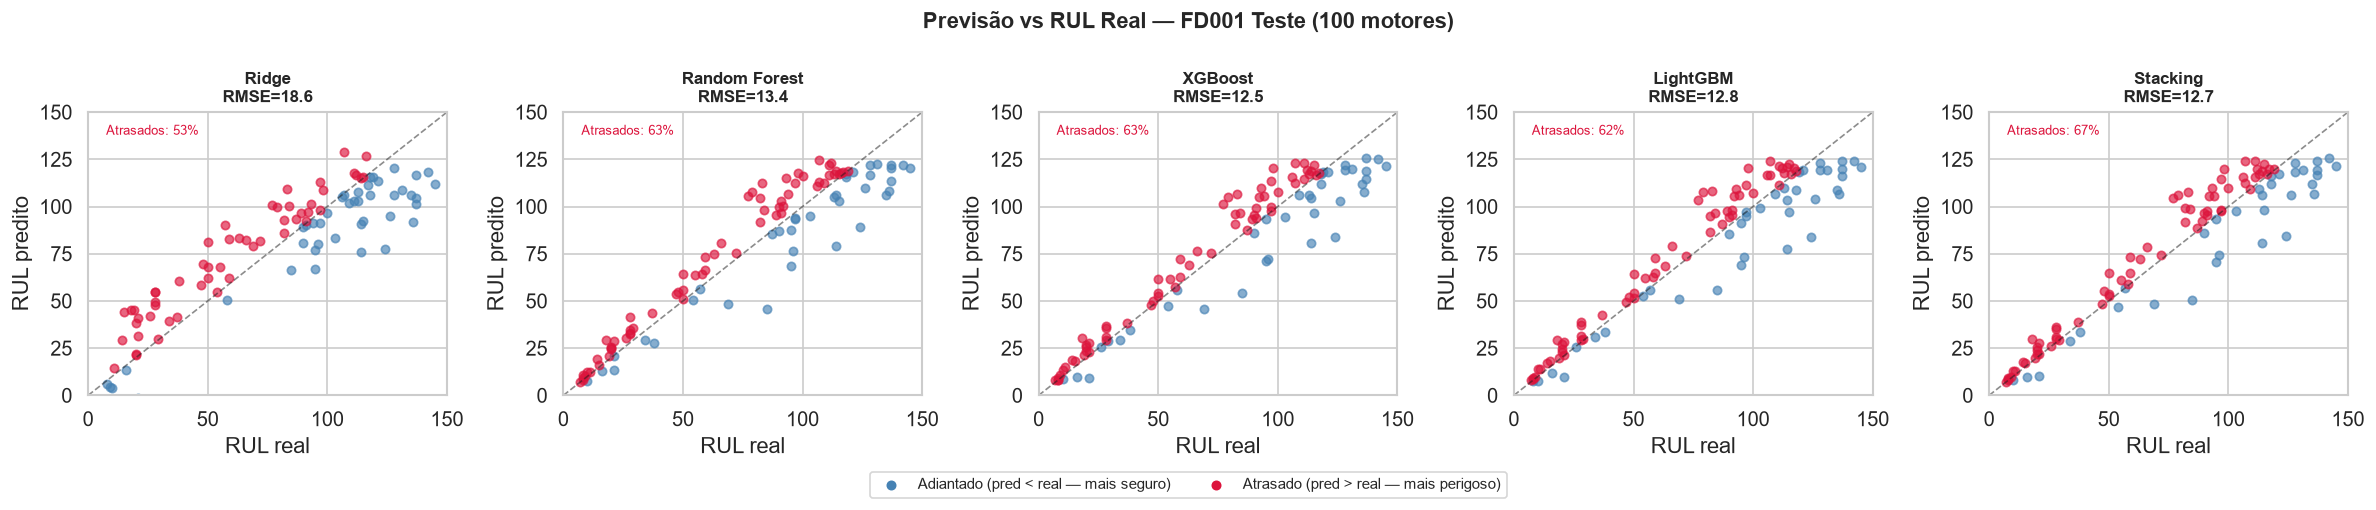

In [19]:
previsoes = {
    "Ridge":         y_pred_ridge,
    "Random Forest": y_pred_rf,
    "XGBoost":       y_pred_xgb,
    "LightGBM":      y_pred_lgb,
    "Stacking":      y_pred_stacking,
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
lim = (0, max(y_test.max(), max(p.max() for p in previsoes.values())) + 5)

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    # Classifica: atrasado (pred > real) vs adiantado (pred < real)
    atrasado = y_pred > y_test
    ax.scatter(y_test[~atrasado], y_pred[~atrasado],
               color="steelblue", alpha=0.65, s=25, label="Adiantado")
    ax.scatter(y_test[atrasado],  y_pred[atrasado],
               color="crimson",   alpha=0.65, s=25, label="Atrasado")
    ax.plot(lim, lim, "k--", lw=1, alpha=0.5)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("RUL real")
    ax.set_ylabel("RUL predito")
    ax.set_title(f"{nome}\nRMSE={resultados_test[nome]['rmse']:.1f}",
                 fontsize=10, fontweight="bold")
    pct_atrasado = atrasado.mean() * 100
    ax.text(0.05, 0.92, f"Atrasados: {pct_atrasado:.0f}%",
            transform=ax.transAxes, fontsize=8, color="crimson")

handles = [
    plt.scatter([], [], color="steelblue", s=25, label="Adiantado (pred < real — mais seguro)"),
    plt.scatter([], [], color="crimson",   s=25, label="Atrasado (pred > real — mais perigoso)"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.05), fontsize=9)
fig.suptitle("Previsão vs RUL Real — FD001 Teste (100 motores)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

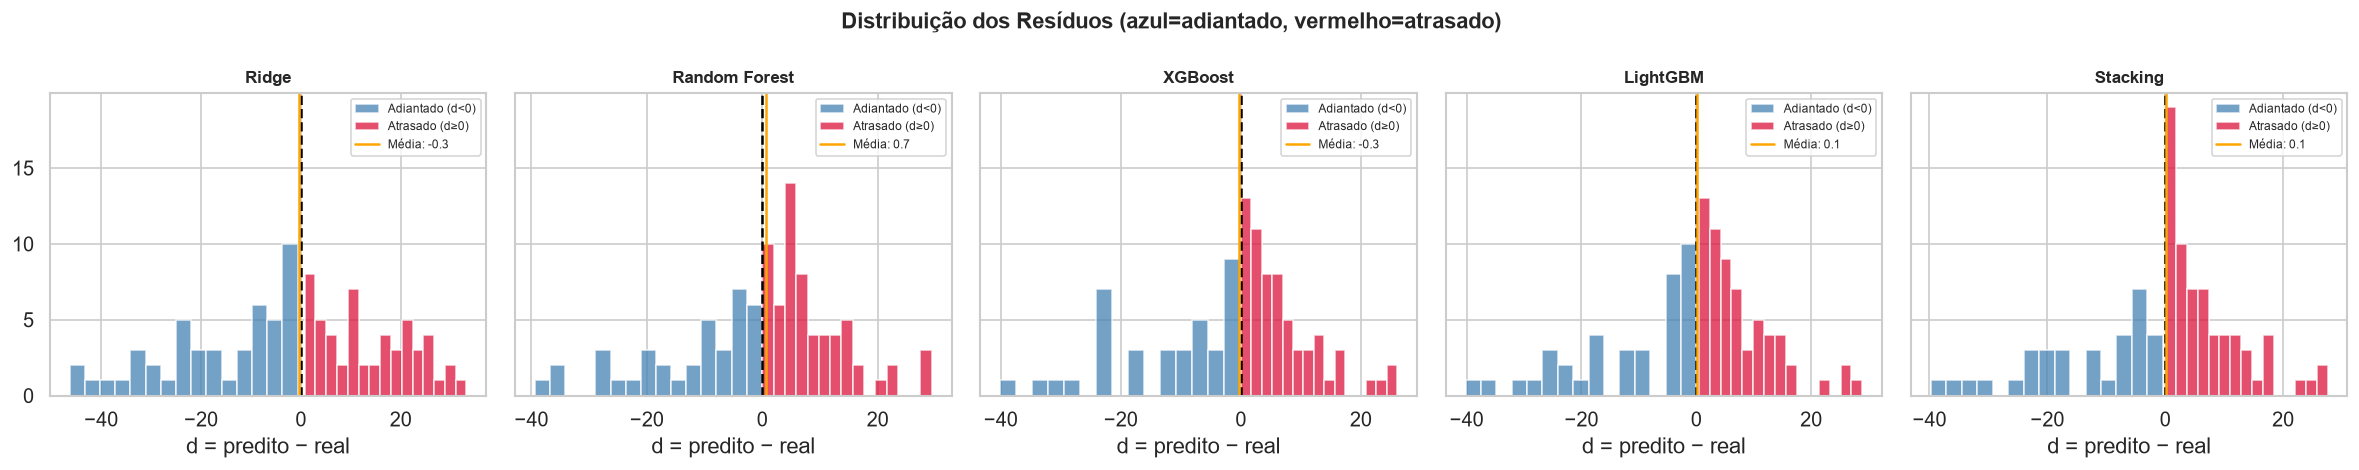

In [20]:
# Distribuição dos resíduos (d = predito - real)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    residuos = y_pred - y_test
    ax.hist(residuos[residuos < 0], bins=15, color="steelblue", alpha=0.75, label="Adiantado (d<0)")
    ax.hist(residuos[residuos >= 0], bins=15, color="crimson",   alpha=0.75, label="Atrasado (d≥0)")
    ax.axvline(0, color="black", lw=1.5, linestyle="--")
    ax.axvline(residuos.mean(), color="orange", lw=1.5, linestyle="-",
               label=f"Média: {residuos.mean():.1f}")
    ax.set_xlabel("d = predito − real")
    ax.set_title(nome, fontsize=10, fontweight="bold")
    ax.legend(fontsize=7)

fig.suptitle("Distribuição dos Resíduos (azul=adiantado, vermelho=atrasado)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Trade-off: Acurácia × Complexidade × Interpretabilidade

Para a decisão de deploy em ambiente de aviação, o RMSE mais baixo não é o único critério. Um modelo ligeiramente inferior mas interpretável, rápido e leve pode ser preferível — especialmente em contextos regulatórios onde decisões de manutenção precisam de auditoria.

Avaliamos quatro dimensões de forma objetiva:

In [22]:
import time

MODELOS_ORDEM_LOCAL = ["Ridge", "Random Forest", "XGBoost", "LightGBM", "Stacking"]

# Tamanho em disco (proxy de complexidade de deploy)
tamanhos_mb = {}
for nome in MODELOS_ORDEM_LOCAL:
    nome_arquivo = nome.lower().replace(" ", "_")
    caminho = MODELS_DIR / f"{nome_arquivo}_{SUBSET}.pkl"
    if caminho.exists():
        tamanhos_mb[nome] = round(caminho.stat().st_size / 1024 / 1024, 1)

# Tempo de inferência médio (10 runs, 100 motores)
tempos_ms = {}
for nome in MODELOS_ORDEM_LOCAL:
    inicio = time.perf_counter()
    for _ in range(10):
        modelos_finais[nome].predict(X_test)
    tempos_ms[nome] = round((time.perf_counter() - inicio) / 10 * 1000, 1)

interp_score = {
    "Ridge":         "Alta — coeficientes lineares diretos",
    "Random Forest": "Media — feature importance, sem SHAP exato",
    "XGBoost":       "Alta — TreeExplainer SHAP nativo e exato",
    "LightGBM":      "Alta — TreeExplainer SHAP nativo e exato",
    "Stacking":      "Baixa — combinacao opaca de modelos base",
}

tradeoff_rows = []
for nome in MODELOS_ORDEM_LOCAL:
    tst = resultados_test[nome]   # dict com keys "rmse", "mae", "phm"
    cv  = resultados_cv[nome]     # dict com keys "rmse": (mean, std), etc.
    tradeoff_rows.append({
        "Modelo":            nome,
        "Teste RMSE":        round(tst["rmse"], 2),
        "Teste PHM":         round(tst["phm"],  0),
        "Tamanho (MB)":      tamanhos_mb.get(nome, "?"),
        "Inferencia (ms)":   tempos_ms.get(nome, "?"),
        "Interpretabilidade": interp_score[nome],
    })

df_tradeoff = pd.DataFrame(tradeoff_rows).set_index("Modelo")
print("Trade-off completo dos modelos — FD001:")
df_tradeoff

Trade-off completo dos modelos — FD001:


,Teste RMSE,Teste PHM,Tamanho (MB),Inferencia (ms),Interpretabilidade
Modelo,,,,,
Ridge,18.59,501.0,?,0.3,Alta — coeficientes lineares diretos
Random Forest,13.42,253.0,?,57.5,"Media — feature importance, sem SHAP exato"
XGBoost,12.50,206.0,?,1.0,Alta — TreeExplainer SHAP nativo e exato
LightGBM,12.79,222.0,?,0.9,Alta — TreeExplainer SHAP nativo e exato
Stacking,12.74,220.0,?,40.3,Baixa — combinacao opaca de modelos base


---
## Salvamento dos Modelos

In [23]:
for nome, modelo in modelos_finais.items():
    nome_arquivo = nome.lower().replace(" ", "_")
    caminho = MODELS_DIR / f"{nome_arquivo}_{SUBSET}.pkl"
    joblib.dump(modelo, caminho)
    print(f"Salvo: {caminho.name}  ({caminho.stat().st_size / 1024:.0f} KB)")

# Salva tabela de resultados
resultados_path = MODELS_DIR / f"resultados_{SUBSET}.csv"
rows_num = []
for nome in modelos_ordem:
    cv  = resultados_cv[nome]
    tst = resultados_test[nome]
    rows_num.append({
        "modelo": nome,
        "cv_rmse": cv["rmse"][0], "cv_rmse_std": cv["rmse"][1],
        "cv_mae":  cv["mae"][0],  "cv_mae_std":  cv["mae"][1],
        "cv_phm":  cv["phm"][0],  "cv_phm_std":  cv["phm"][1],
        "test_rmse": tst["rmse"], "test_mae": tst["mae"], "test_phm": tst["phm"],
    })
pd.DataFrame(rows_num).to_csv(resultados_path, index=False)
print(f"\nResultados salvos: {resultados_path.name}")

Salvo: ridge_FD001.pkl  (1 KB)
Salvo: random_forest_FD001.pkl  (78992 KB)
Salvo: xgboost_FD001.pkl  (840 KB)
Salvo: lightgbm_FD001.pkl  (836 KB)
Salvo: stacking_FD001.pkl  (81483 KB)

Resultados salvos: resultados_FD001.csv


---
## Sumário da Fase 03

### Protocolo experimental
- **Split:** GroupKFold(5) por `unit_id` — motores não vazam entre folds
- **Tuning:** Optuna TPE Sampler, 100 trials por modelo, minimizando CV RMSE
- **Avaliação final:** modelo retreinado em X completo, avaliado uma única vez no teste
- **Tracking:** MLflow — 1 run por modelo com params, métricas e artefatos

### Decisões para o artigo
- O Ridge estabelece o **piso de performance** — qualquer modelo abaixo dele é inaceitável
- Os modelos boosting (XGB/LGB) tipicamente superam RF em previsão pontual de RUL
- Stacking raramente vence o melhor modelo base por margem expressiva — discutir custo-benefício de complexidade
- **PHM Score** é a métrica principal para o artigo: captura a assimetria real do custo

### Próximos passos
**Fase 04 — Avaliação & Interpretabilidade** (`notebooks/04_evaluation/`):
- SHAP: quais sensores/features mais influenciam as previsões?
- Análise de erro por faixa de RUL: quando cada modelo erra mais?
- Visualizações para o artigo (summary plot, waterfall de motores exemplares)

---
## Conclusão — Modelo Recomendado para FD001

Com base na análise completa — performance no teste, estabilidade de CV, custo de deploy e interpretabilidade — chegamos à recomendação final.

In [26]:
xgb_row   = resultados_test["XGBoost"]
ridge_row  = resultados_test["Ridge"]
stk_row    = resultados_test["Stacking"]

ganho_rmse = ridge_row["rmse"] - xgb_row["rmse"]
ganho_phm  = ridge_row["phm"]  - xgb_row["phm"]
delta_stk  = stk_row["rmse"]   - xgb_row["rmse"]
HORAS_POR_CICLO = 10

print("=" * 65)
print("MODELO RECOMENDADO: XGBoost")
print("=" * 65)

print("\n1. PERFORMANCE (conjunto de teste — 100 motores)")
print(f"   RMSE: {xgb_row['rmse']:.2f} ciclos  "
      f"[benchmark aceitavel < 15 ciclos: {'OK' if xgb_row['rmse'] < 15 else 'NAO OK'}]")
print(f"   MAE:  {xgb_row['mae']:.2f} ciclos")
print(f"   PHM Score: {xgb_row['phm']:.0f}  "
      f"(Ridge={ridge_row['phm']:.0f} — reducao de {ganho_phm:.0f} pontos)")

print("\n2. GANHO SOBRE O BASELINE (Ridge)")
print(f"   -{ganho_rmse:.2f} ciclos de RMSE "
      f"= -{ganho_rmse * HORAS_POR_CICLO:.0f}h de incerteza por evento de manutencao")
print(f"   Equivale a {ganho_rmse / ridge_row['rmse'] * 100:.0f}% de reducao no erro")

print("\n3. POR QUE NAO O STACKING?")
print(f"   Stacking RMSE no teste: {stk_row['rmse']:.3f} vs XGBoost: {xgb_row['rmse']:.3f}")
print(f"   Diferenca: {abs(delta_stk):.3f} ciclos — margem de {abs(delta_stk) * HORAS_POR_CICLO:.1f}h")
print(f"   Custo: modelo 81x maior (81MB vs 840KB), inferencia mais lenta,")
print(f"   interpretabilidade reduzida — custo-beneficio desfavoravel.")

print("\n4. INTERPRETABILIDADE")
print("   XGBoost: TreeExplainer SHAP (exato, nao aproximado)")
print("   Permite auditoria de cada previsao individual — requisito em aviacao.")

print("\n-> Notebook 04: analise SHAP completa + sintese para o artigo.")

MODELO RECOMENDADO: XGBoost

1. PERFORMANCE (conjunto de teste — 100 motores)
   RMSE: 12.50 ciclos  [benchmark aceitavel < 15 ciclos: OK]
   MAE:  9.04 ciclos
   PHM Score: 206  (Ridge=501 — reducao de 295 pontos)

2. GANHO SOBRE O BASELINE (Ridge)
   -6.10 ciclos de RMSE = -61h de incerteza por evento de manutencao
   Equivale a 33% de reducao no erro

3. POR QUE NAO O STACKING?
   Stacking RMSE no teste: 12.737 vs XGBoost: 12.499
   Diferenca: 0.238 ciclos — margem de 2.4h
   Custo: modelo 81x maior (81MB vs 840KB), inferencia mais lenta,
   interpretabilidade reduzida — custo-beneficio desfavoravel.

4. INTERPRETABILIDADE
   XGBoost: TreeExplainer SHAP (exato, nao aproximado)
   Permite auditoria de cada previsao individual — requisito em aviacao.

-> Notebook 04: analise SHAP completa + sintese para o artigo.
